# Linear Combinations of Unitaries

Workspace for testing converting reward-atoms values into non-unitary matrix, then converting that matrix to a linear combination of unitaries (LCU).

In [20]:
import pennylane as qml
from pennylane import math as qml_math
from pennylane import numpy as np
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.visualization import array_to_latex
from typing import Callable
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from functools import reduce
from scipy.stats import wasserstein_distance

In [21]:
rng = np.random.default_rng(42)

In [22]:
dev = qml.device("default.qubit")
# dev = qml.device("default.mixed")
# dev = qml.device("default.qubit", shots=10000)
# dev = qml.device("default.qubit", shots=None)

In [23]:
def is_unitary(m: np.ndarray):
    return np.allclose(np.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: np.ndarray):
    return np.allclose(m, m.T.conj())

def is_sorted(x: np.ndarray):
    x = np.array(x)
    return bool(np.all(x[:-1] <= x[1:]))

def softmax(x: np.ndarray):
    y = np.exp(x - np.max(x)) # Stabilize to prevent overflow.
    return y / np.sum(y)

In [24]:
from typing import Any


@qml.qnode(dev)
def circuit(
    wires: list[int],
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)

In [25]:
def prepare_action_returns(
    wires: list[int], 
    action_probs_vec: np.ndarray, # shape (n_actions,),
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    ):
    # print(f"{action_probs_vec.shape=}")
    # print(f"{returns_probs_matrix.shape=}")
    n_actions = action_probs_vec.shape[0]
    n_returns = returns_probs_matrix.shape[1]
    
    # Get number of qubits needed for actions and returns.
    # (for now) The number of actions and returns must be powers of 2 for this to work properly.
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Partition wires into action and return wires.
    # Wire order is: [action wires, return wires]
    if len(wires) != d_actions + d_returns:
        raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
    wires_action = wires[:d_actions]
    wires_returns = wires[d_actions:]
    # print(f"{wires_action=}, {wires_returns=}")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_action, normalize=False) # Must normalize since inputs are probability vectors.
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=False) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_action)

In [26]:
n_actions = 2 # 4
n_returns = 4 # 8
d_actions = int(np.log2(n_actions))
d_returns = int(np.log2(n_returns))

In [27]:
returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

# returns_probs_matrix[[0,3]] = returns_probs_matrix[[3,0]] # Swap some rows.

In [28]:
# returns_atoms_values_original = np.array([1./n_returns]*n_returns) # DOES NOT WORK!
returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/2.) # This works. Monotonically increasing/decreasing probability distribution.
returns_atoms_values = returns_atoms_values_original.copy()

# returns_atoms_values = returns_atoms_values_original.copy() # DOES NOT WORK. Must at least have square-root term.
returns_atoms_values = np.sqrt(returns_atoms_values) # This is minimal working representation. Must at least have square-root of probability distribution. Causes L2-norm of diagonal unitary to be 1.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_actions) # causes a 1:1 match with computing weighted action distribution via expected return.
# returns_atoms_values = np.sqrt(returns_atoms_values*(n_actions*n_returns)/(d_actions*d_returns)*2)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions # causes L2-norm of circuit probs to be close to 1.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_returns/n_actions)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)
# returns_atoms_values = returns_atoms_values + 1j*np.sqrt(1 - returns_atoms_values**2.) # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.sqrt(1 - returns_atoms_values**2.) + 1j*returns_atoms_values # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.exp(2*np.pi*1j*returns_atoms_values)
# returns_atoms_values = returns_atoms_values / np.linalg.norm(returns_atoms_values)
# returns_atoms_values = np.exp(1j*returns_atoms_values)

# # Swap real/imaginary parts.
# r = returns_atoms_values.real.copy()
# i = returns_atoms_values.imag.copy()
# returns_atoms_values.real = i
# returns_atoms_values.imag = r

U_returns_atoms = np.diag(returns_atoms_values)

In [29]:
action_probs_vec = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec = np.array(action_probs_vec) # Convert to numpy array for vectorization.

In [ ]:
################### LCU - TEST/TEST/TEST
wires = list(range(d_actions + d_returns + d_returns))
wires_actions = wires[:d_actions]
wires_returns = wires[d_actions:-d_returns]
wires_lcu = list(set(wires) - (set(wires_actions).union(set(wires_returns))))
print(f"{d_actions=}")
print(f"{d_returns=}")
print(f"{wires=}")
print(f"{wires_actions=}")
print(f"{wires_returns=}")
print(f"{wires_lcu=}")

LCU_coeffs, LCU_ops = qml.pauli_decompose(U_returns_atoms, wire_order=wires_returns).terms()

# LCU_coeffs = np.abs(LCU_coeffs)
alphas = (np.sqrt(LCU_coeffs) / np.linalg.norm(np.sqrt(LCU_coeffs)))
print(f"{LCU_coeffs=}")
print(f"{alphas=}")
print(f"{LCU_ops=}")

funcs = [
    # lambda wires: prepare_action_returns(wires_actions+wires_returns, action_probs_vec, returns_probs_matrix), # Prepare the action and return distributions.
    ####
    # lambda wires: qml.StatePrep(alphas, wires=wires_lcu),
    # lambda wires: qml.Select(LCU_ops, control=wires_lcu),
    # lambda wires: qml.adjoint(qml.StatePrep(alphas, wires=wires_lcu)),
    ####
    lambda wires: qml.PrepSelPrep(qml.pauli_decompose(U_returns_atoms, wire_order=wires_returns), control=wires_lcu),
]

func_measure = lambda wires: (
    qml.state(),
    qml.probs(wires=wires),
    # qml.density_matrix(wires),
    qml.probs(wires=wires_actions),
    qml.probs(wires=wires_returns),
    # qml.probs(wires=wires_returns[:-1]),
    # *[qml.expval(qml.PauliZ(wires=i)) for i in range(d_actions)],
    # *[qml.expval(qml.PauliZ(wires=i)) for i in range(d_returns)],
    # qml.probs(wires=wires_returns, op=qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True))
    # qml.probs(wires=wires_returns, op=qml.DiagonalQubitUnitary(returns_atoms_values, wires=wires_returns))
    # qml.probs(op=qml.Identity(wires=wires_actions)@qml.Hermitian(U_returns_atoms, wires=wires_returns))
    # qml.probs(op=qml.Hermitian(U_returns_atoms, wires=wires_returns))
    ) # Tuple of measurements: state, probs, density matrix, probs actions, probs returns.
(
    state,
    probs,
    # rho,
    probs_actions,
    probs_returns,
    # exp_actions,
    # exp_returns,
    # test_probs_actions,
    ) = circuit(wires, funcs=funcs, func_measure=func_measure)

display(Statevector(state).draw(output='latex', prefix="\\textrm{State:~~}"))
display(array_to_latex(probs, prefix="\\textrm{Probabilities:~~}"))
display(array_to_latex(probs_actions, prefix="\\textrm{Action Probabilities:~~}"))
output_matrix = qml.matrix(circuit, wire_order=wires)(wires, funcs=funcs, func_measure=func_measure)
################### LCU - TEST/TEST/TEST

d_actions=1
d_returns=2
wires=[0, 1, 2, 3, 4]
wires_actions=[0]
wires_returns=[1, 2]
wires_lcu=[3, 4]
LCU_coeffs=tensor([ 0.48193439, -0.05992999, -0.11803473,  0.01467797], requires_grad=True)
alphas=tensor([nan, nan, nan, nan], requires_grad=True)
LCU_ops=[I(1) @ I(2), I(1) @ Z(2), Z(1) @ I(2), Z(1) @ Z(2)]


/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/numpy/tensor.py:155: RuntimeWarning: invalid value encountered in sqrt
  res = super().__array_ufunc__(ufunc, method, *args, **kwargs)


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/numpy/tensor.py:155: RuntimeWarning: divide by zero encountered in matmul
  res = super().__array_ufunc__(ufunc, method, *args, **kwargs)
/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/numpy/tensor.py:155: RuntimeWarning: overflow encountered in matmul
  res = super().__array_ufunc__(ufunc, method, *args, **kwargs)
/Users/derieux/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/numpy/tensor.py:155: RuntimeWarning: invalid value encountered in matmul
  res = super().__array_ufunc__(ufunc, method, *args, **kwargs)


(<Figure size 400x600 with 1 Axes>, <Axes: >)

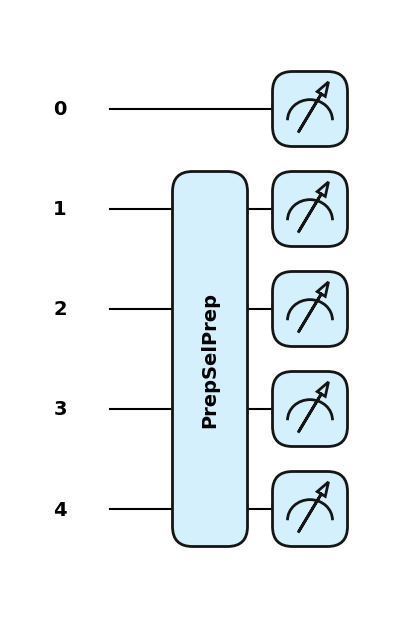

In [31]:
qml.draw_mpl(circuit, wire_order=wires, style='pennylane')(wires, funcs=funcs, func_measure=func_measure)

In [57]:
from pennylane.math import partial_trace
output_matrix_reduced = partial_trace(output_matrix, indices=wires_actions)
output_matrix_reduced.shape, output_matrix_reduced

((16, 16),
 tensor([[ 9.44733105e-01+6.46164612e-17j,
          -7.60918605e-01+4.65928267e-17j,
          -1.23838685e+00+7.58293248e-17j,
           9.97436834e-01-6.10753913e-17j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j],
         [-7.60918605e-01+4.65928267e-17j,
          -9.44733105e-01+1.80312899e-16j,
           9.97436834e-01-6.10753913e-17j,
           1.23838685e+00-7.58293248e-17j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,
           0.00000000e+00+0.00000000e+00j,

In [60]:
display(array_to_latex(np.real(output_matrix), max_size=32))

<IPython.core.display.Latex object>

In [63]:
display(array_to_latex(np.real(output_matrix_reduced), max_size=32))

<IPython.core.display.Latex object>

In [62]:
lcu = qml.pauli_decompose(U_returns_atoms, wire_order=wires_returns)
# qml.matrix(lcu)
display(array_to_latex(qml.matrix(lcu).real / sum(abs(np.array(lcu.terms()[0])))))

<IPython.core.display.Latex object>

In [61]:
display(array_to_latex(U_returns_atoms))

<IPython.core.display.Latex object>

In [41]:
U_returns_atoms.diagonal()

tensor([0.31864765, 0.40915168, 0.52536116, 0.67457708], requires_grad=True)

In [45]:
returns_atoms_values_original

tensor([0.10153632, 0.1674051 , 0.27600434, 0.45505423], requires_grad=True)

In [46]:
returns_atoms_values

tensor([0.31864765, 0.40915168, 0.52536116, 0.67457708], requires_grad=True)

In [48]:
np.linalg.norm(returns_atoms_values)

np.float64(0.9999999999999999)

In [47]:
np.linalg.norm(U_returns_atoms.diagonal())

np.float64(0.9999999999999999)

In [44]:
U_returns_atoms.diagonal()/np.linalg.norm(U_returns_atoms.diagonal())

tensor([0.31864765, 0.40915168, 0.52536116, 0.67457708], requires_grad=True)

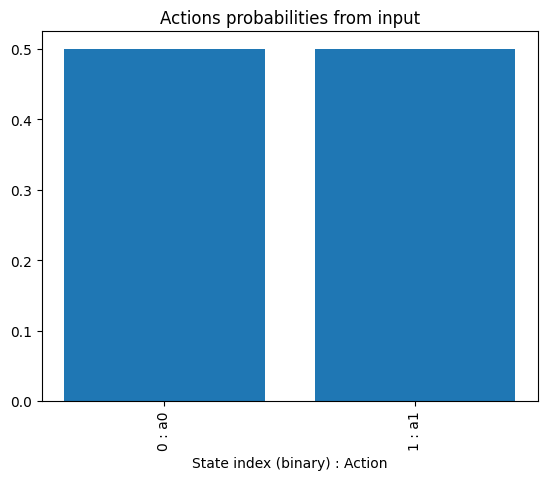

<Figure size 640x480 with 0 Axes>

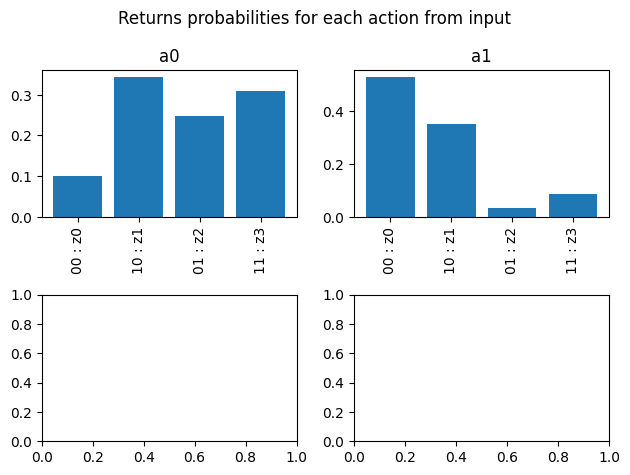

Text(0.5, 0, 'State index (binary) : Action')

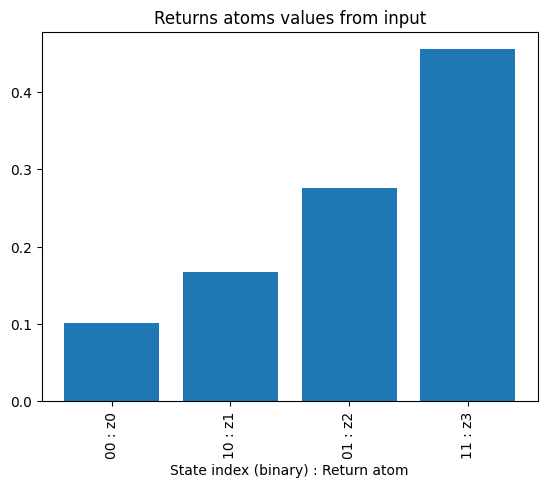

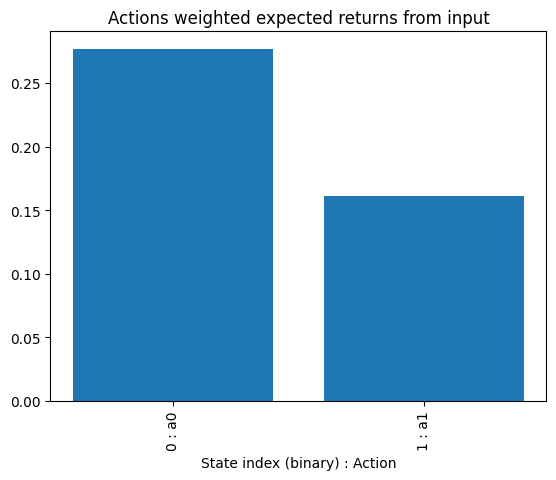

In [34]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(np.arange(n_actions), action_probs_vec)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions probabilities from input")
plt.xlabel("State index (binary) : Action")


plt.figure()
d = int(np.ceil(np.sqrt(n_actions)))
fig, axs = plt.subplots(d, d)
axs = axs.flatten()
for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), returns_probs_matrix[a])
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}")
plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()


plt.figure()
plt.bar(np.arange(n_returns), returns_atoms_values_original)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title("Returns atoms values from input")
plt.xlabel("State index (binary) : Return atom")


plt.figure()
plt.bar(np.arange(n_actions), returns_probs_matrix @ returns_atoms_values_original)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions weighted expected returns from input")
plt.xlabel("State index (binary) : Action")

Text(0.5, 0, 'State index (binary) : Action')

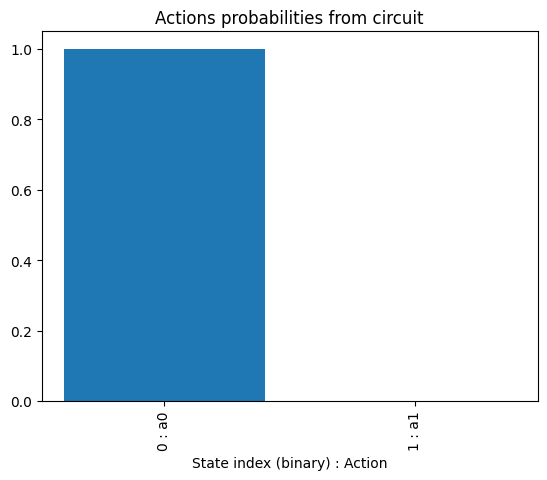

In [35]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title("Actions probabilities from circuit")
plt.xlabel("State index (binary) : Action")

In [36]:
### Rank actions from high-to-low based on their weighted expected return.

# sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]
action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1])
action_rank_manual_compute

(0, 1)

In [37]:
### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1])
action_rank_circuit_probs

(0, 1)

In [38]:
### Verify manually computed action rank is the same as the rank estimated by the circuit.

action_rank_manual_compute == action_rank_circuit_probs

True